In [8]:

import pandas as pd
import numpy as np

np.random.seed(42)

n = 10000

levels = np.random.choice(
    [1, 2, 3, 4, 5],
    size=n,
    p=[0.25, 0.23, 0.20, 0.18, 0.14]
)

difficulty_map = {1: 1, 2: 2, 3: 3, 4: 4, 5: 5}
difficulty = np.array([difficulty_map[x] for x in levels])

players = np.random.randint(1, 2001, n)

playtime = np.maximum(
    2, np.random.normal(10 + difficulty * 2, 4, n)
).round(2)

deaths = np.random.poisson(difficulty * 0.8)

score = np.maximum(
    0, (1000 - difficulty * 100 +
        np.random.normal(0, 200, n) - deaths * 40)
).astype(int)

weapons = np.random.choice(
    ["Pistol", "Rifle", "Shotgun", "Sniper"],
    size=n,
    p=[0.2, 0.4, 0.25, 0.15]
)

quit_prob = np.clip(0.05 + difficulty * 0.055 +
                    deaths * 0.015, 0, 0.8)

outcome = np.where(
    np.random.random(n) < quit_prob,
    "Quit", "Completed"
)

df = pd.DataFrame({
    "player_id": players,
    "session_id": range(1, n + 1),
    "level": levels,
    "playtime_min": playtime,
    "deaths": deaths,
    "score": score,
    "weapon": weapons,
    "outcome": outcome,
    "difficulty": difficulty
})

df.to_csv("gameplay_data.csv", index=False)

print("Dataset generated successfully!")
print(df.head())
print("Dataset shape:", df.shape)


Dataset generated successfully!
   player_id  session_id  level  playtime_min  deaths  score   weapon  \
0       1207           1      2         10.18       3    816  Shotgun   
1        864           2      5         17.86       4     38    Rifle   
2        548           3      4         14.30       5    363    Rifle   
3       1906           4      3         15.13       2    393   Sniper   
4       1061           5      1          4.03       1   1055  Shotgun   

     outcome  difficulty  
0  Completed           2  
1       Quit           5  
2       Quit           4  
3       Quit           3  
4  Completed           1  
Dataset shape: (10000, 9)


In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Load dataset
df = pd.read_csv("gameplay_data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (10000, 9)


,player_id,session_id,level,playtime_min,deaths,score,weapon,outcome,difficulty
0,1207,1,2,10.18,3,816,Shotgun,Completed,2
1,864,2,5,17.86,4,38,Rifle,Quit,5
2,548,3,4,14.30,5,363,Rifle,Quit,4
3,1906,4,3,15.13,2,393,Sniper,Quit,3
4,1061,5,1,4.03,1,1055,Shotgun,Completed,1


In [10]:

# Original dataset size
print("Original shape:", df.shape)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicates
print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates().copy()

# Remove rows with missing required values
required_cols = [
    "player_id", "session_id", "level",
    "playtime_min", "deaths", "score",
    "weapon", "outcome", "difficulty"
]
df = df.dropna(subset=required_cols).copy()

# Ensure correct data types
df["player_id"] = df["player_id"].astype(int)
df["session_id"] = df["session_id"].astype(int)
df["level"] = df["level"].astype(int)
df["deaths"] = df["deaths"].astype(int)
df["score"] = df["score"].astype(int)

# Validate values
df = df[
    (df["level"].between(1, 5)) &
    (df["playtime_min"] > 0) &
    (df["deaths"] >= 0) &
    (df["score"] >= 0) &
    (df["outcome"].isin(["Completed", "Quit"]))
].copy()

# Derived features
df["completion"] = (df["outcome"] == "Completed").astype(int)
df["death_rate_per_min"] = (
    df["deaths"] / df["playtime_min"]
)

print("\nCleaned shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
display(df.head())


Original shape: (10000, 9)

Missing values:
player_id       0
session_id      0
level           0
playtime_min    0
deaths          0
score           0
weapon          0
outcome         0
difficulty      0
dtype: int64

Duplicate rows: 0

Cleaned shape: (10000, 11)
Remaining missing values: 0


,player_id,session_id,level,playtime_min,deaths,score,weapon,outcome,difficulty,completion,death_rate_per_min
0,1207,1,2,10.18,3,816,Shotgun,Completed,2,1,0.294695
1,864,2,5,17.86,4,38,Rifle,Quit,5,0,0.223964
2,548,3,4,14.30,5,363,Rifle,Quit,4,0,0.349650
3,1906,4,3,15.13,2,393,Sniper,Quit,3,0,0.132188
4,1061,5,1,4.03,1,1055,Shotgun,Completed,1,1,0.248139


In [11]:

total_sessions = len(df)
unique_players = df["player_id"].nunique()
total_deaths = df["deaths"].sum()
avg_playtime = df["playtime_min"].mean()
avg_score = df["score"].mean()
completion_rate = df["completion"].mean() * 100
quit_rate = 100 - completion_rate

print("===== GAMEPLAY OVERVIEW =====")
print("Total Sessions:", total_sessions)
print("Unique Players:", unique_players)
print("Total Deaths:", total_deaths)
print(f"Average Playtime: {avg_playtime:.2f} min")
print(f"Average Score: {avg_score:.2f}")
print(f"Completion Rate: {completion_rate:.2f}%")
print(f"Quit Rate: {quit_rate:.2f}%")


===== GAMEPLAY OVERVIEW =====
Total Sessions: 10000
Unique Players: 1993
Total Deaths: 21751
Average Playtime: 15.41 min
Average Score: 639.55
Completion Rate: 76.83%
Quit Rate: 23.17%


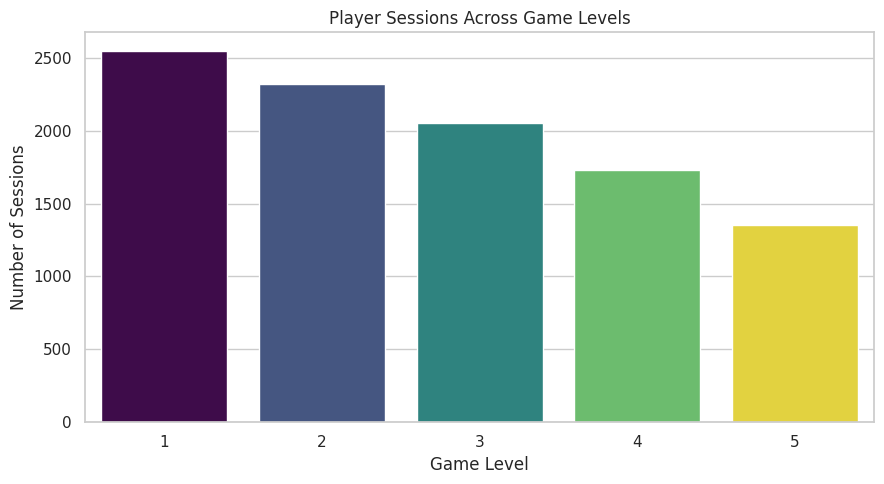

,level,sessions,avg_deaths,avg_playtime,avg_score,completion_rate,quit_rate
0,1,2547,0.82,12.03,865.11,87.95,12.05
1,2,2317,1.64,13.99,729.58,81.96,18.04
2,3,2055,2.43,15.92,601.42,75.33,24.67
3,4,1727,3.19,18.11,463.98,67.86,32.14
4,5,1354,3.95,19.97,342.98,60.86,39.14


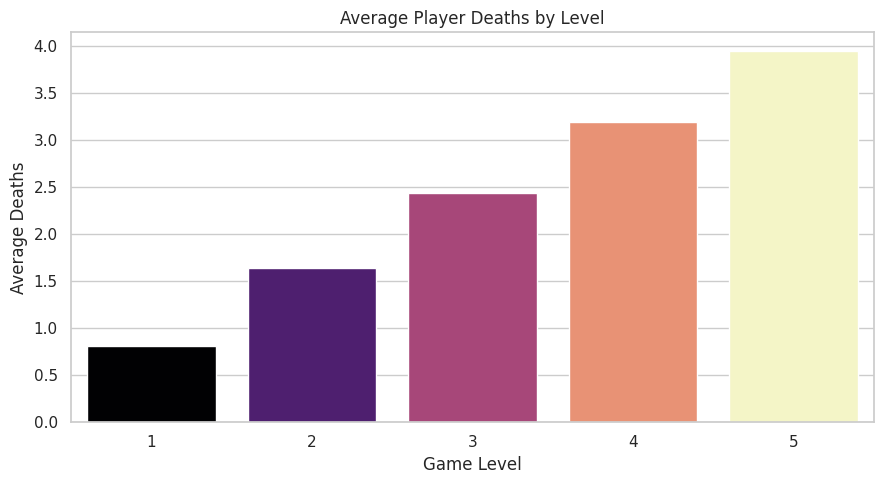

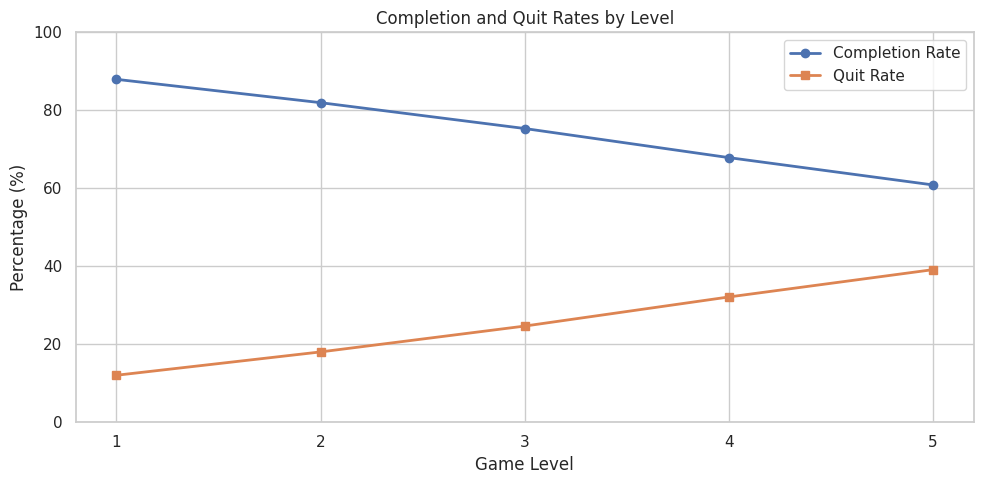

In [12]:

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="level", hue="level", palette="viridis", legend=False)
plt.title("Player Sessions Across Game Levels")
plt.xlabel("Game Level")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()


level_stats = df.groupby("level").agg(
    sessions=("session_id", "count"),
    avg_deaths=("deaths", "mean"),
    avg_playtime=("playtime_min", "mean"),
    avg_score=("score", "mean"),
    completion_rate=("completion", "mean")
).reset_index()

level_stats["completion_rate"] *= 100
level_stats["quit_rate"] = 100 - level_stats["completion_rate"]

display(level_stats.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=level_stats,
    x="level",
    y="avg_deaths",
    hue="level",
    palette="magma",
    legend=False
)
plt.title("Average Player Deaths by Level")
plt.xlabel("Game Level")
plt.ylabel("Average Deaths")
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))
plt.plot(
    level_stats["level"],
    level_stats["completion_rate"],
    marker="o",
    linewidth=2,
    label="Completion Rate"
)
plt.plot(
    level_stats["level"],
    level_stats["quit_rate"],
    marker="s",
    linewidth=2,
    label="Quit Rate"
)
plt.title("Completion and Quit Rates by Level")
plt.xlabel("Game Level")
plt.ylabel("Percentage (%)")
plt.xticks(level_stats["level"])
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()


,weapon,usage,avg_score,avg_deaths,completion_rate
0,Pistol,1970,636.52,2.21,77.21
1,Rifle,4000,639.87,2.15,75.95
2,Shotgun,2524,639.29,2.24,77.81
3,Sniper,1506,643.08,2.10,77.03


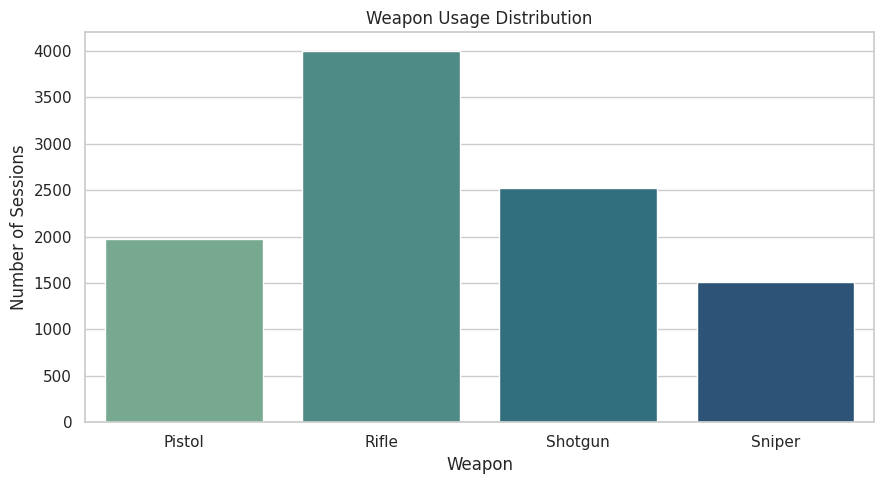

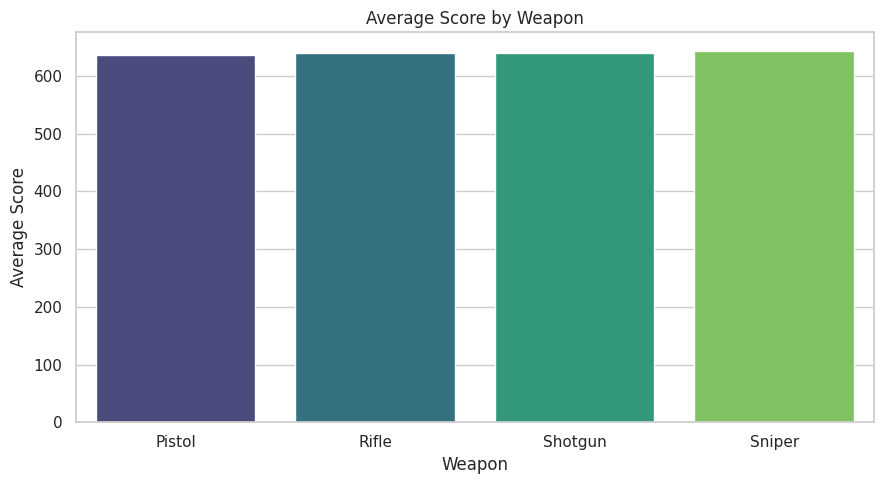

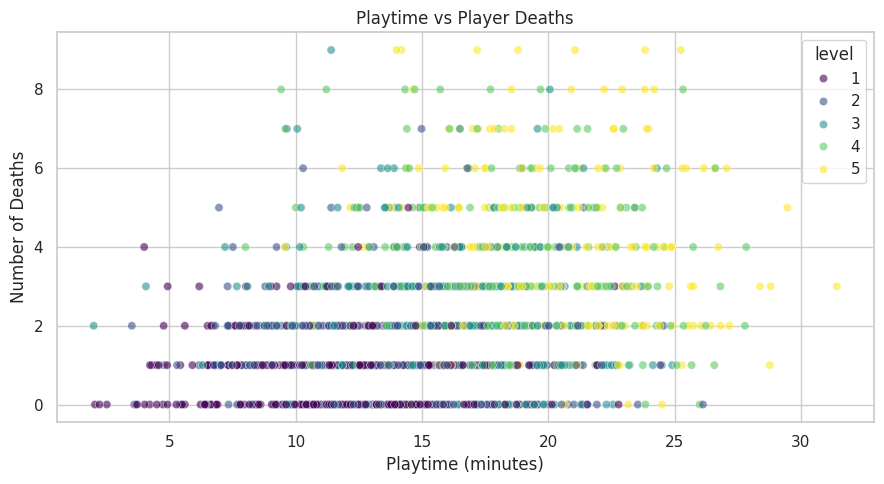

In [13]:

weapon_stats = df.groupby("weapon").agg(
    usage=("session_id", "count"),
    avg_score=("score", "mean"),
    avg_deaths=("deaths", "mean"),
    completion_rate=("completion", "mean")
).reset_index()

weapon_stats["completion_rate"] *= 100
display(weapon_stats.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=weapon_stats,
    x="weapon",
    y="usage",
    hue="weapon",
    palette="crest",
    legend=False
)
plt.title("Weapon Usage Distribution")
plt.xlabel("Weapon")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))
sns.barplot(
    data=weapon_stats,
    x="weapon",
    y="avg_score",
    hue="weapon",
    palette="viridis",
    legend=False
)
plt.title("Average Score by Weapon")
plt.xlabel("Weapon")
plt.ylabel("Average Score")
plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df.sample(min(1500, len(df)), random_state=42),
    x="playtime_min",
    y="deaths",
    hue="level",
    palette="viridis",
    alpha=0.6
)
plt.title("Playtime vs Player Deaths")
plt.xlabel("Playtime (minutes)")
plt.ylabel("Number of Deaths")
plt.tight_layout()
plt.show()


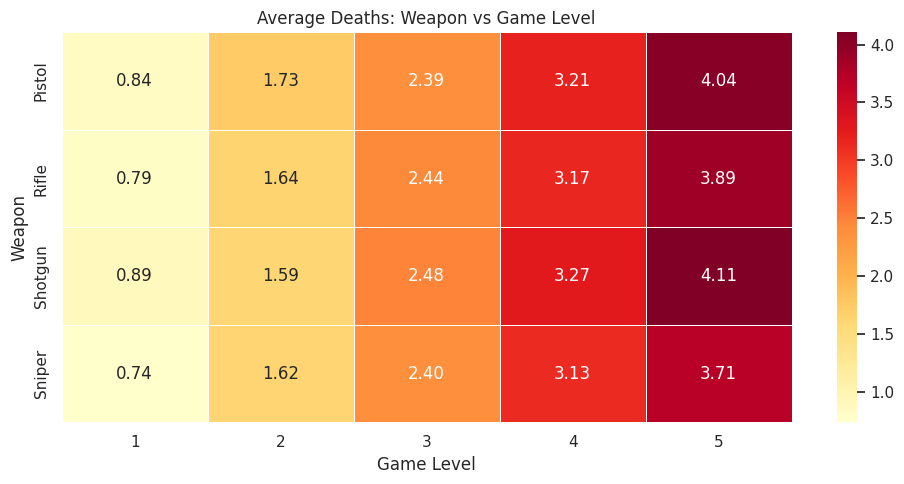

In [14]:

# Average deaths for each weapon at each level
difficulty_heatmap = df.pivot_table(
    index="weapon",
    columns="level",
    values="deaths",
    aggfunc="mean"
)

plt.figure(figsize=(10, 5))
sns.heatmap(
    difficulty_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5
)
plt.title("Average Deaths: Weapon vs Game Level")
plt.xlabel("Game Level")
plt.ylabel("Weapon")
plt.tight_layout()
plt.show()



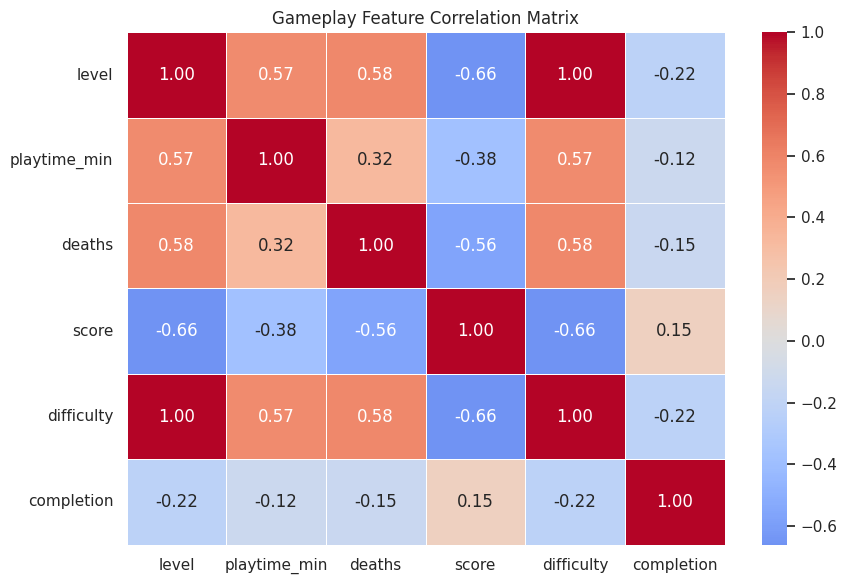

Correlation with score:
score           1.000000
completion      0.152915
playtime_min   -0.378978
deaths         -0.562361
level          -0.660512
difficulty     -0.660512
Name: score, dtype: float64


In [15]:

numeric_cols = [
    "level", "playtime_min", "deaths",
    "score", "difficulty", "completion"
]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    linewidths=0.5
)
plt.title("Gameplay Feature Correlation Matrix")
plt.tight_layout()
plt.show()

print("Correlation with score:")
print(correlation["score"].sort_values(ascending=False))


In [16]:

hardest_level = level_stats.loc[
    level_stats["avg_deaths"].idxmax()
]

highest_quit_level = level_stats.loc[
    level_stats["quit_rate"].idxmax()
]

highest_score_weapon = weapon_stats.loc[
    weapon_stats["avg_score"].idxmax()
]

most_used_weapon = weapon_stats.loc[
    weapon_stats["usage"].idxmax()
]

print("===== GAME ANALYTICS INSIGHTS =====")

print(
    f"Level {int(hardest_level['level'])} has "
    f"the highest average deaths: "
    f"{hardest_level['avg_deaths']:.2f}"
)

print(
    f"Level {int(highest_quit_level['level'])} has "
    f"the highest quit rate: "
    f"{highest_quit_level['quit_rate']:.2f}%"
)

print(
    f"{highest_score_weapon['weapon']} has the highest "
    f"average score: {highest_score_weapon['avg_score']:.2f}"
)

print(
    f"{most_used_weapon['weapon']} is the most-used weapon "
    f"with {int(most_used_weapon['usage'])} sessions"
)

print(
    f"Overall completion rate: {completion_rate:.2f}%"
)

print(
    f"Average playtime: {avg_playtime:.2f} minutes"
)


===== GAME ANALYTICS INSIGHTS =====
Level 5 has the highest average deaths: 3.95
Level 5 has the highest quit rate: 39.14%
Sniper has the highest average score: 643.08
Rifle is the most-used weapon with 4000 sessions
Overall completion rate: 76.83%
Average playtime: 15.41 minutes


In [17]:

df.to_csv("cleaned_gameplay_data.csv", index=False)
level_stats.to_csv("level_analysis.csv", index=False)
weapon_stats.to_csv("weapon_analysis.csv", index=False)

print("All analysis files exported successfully!")


All analysis files exported successfully!


In [18]:

import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import pandas as pd

# Interactive filters
level_filter = widgets.Dropdown(
    options=["All"] + sorted(df["level"].unique().tolist()),
    value="All",
    description="Level:"
)

weapon_filter = widgets.Dropdown(
    options=["All"] + sorted(df["weapon"].unique().tolist()),
    value="All",
    description="Weapon:"
)

outcome_filter = widgets.Dropdown(
    options=["All"] + sorted(df["outcome"].unique().tolist()),
    value="All",
    description="Outcome:"
)

output = widgets.Output()

def update_dashboard(level, weapon, outcome):
    with output:
        clear_output(wait=True)

        filtered = df.copy()

        if level != "All":
            filtered = filtered[filtered["level"] == level]
        if weapon != "All":
            filtered = filtered[filtered["weapon"] == weapon]
        if outcome != "All":
            filtered = filtered[filtered["outcome"] == outcome]

        if filtered.empty:
            print("No data available for these filters.")
            return

        total = len(filtered)
        completion = (filtered["outcome"] == "Completed").mean() * 100
        avg_score = filtered["score"].mean()
        avg_deaths = filtered["deaths"].mean()

        print("🎮 GAME PLAYER ANALYTICS DASHBOARD")
        print("-" * 40)
        print(f"Total Sessions: {total:,}")
        print(f"Completion Rate: {completion:.2f}%")
        print(f"Average Score: {avg_score:.2f}")
        print(f"Average Deaths: {avg_deaths:.2f}")

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        filtered.groupby("level")["deaths"].mean().plot(
            kind="bar", ax=axes[0], title="Average Deaths by Level"
        )
        axes[0].set_ylabel("Average Deaths")
        axes[0].set_xlabel("Level")

        filtered.groupby("weapon")["score"].mean().plot(
            kind="bar", ax=axes[1], title="Average Score by Weapon"
        )
        axes[1].set_ylabel("Average Score")
        axes[1].set_xlabel("Weapon")

        plt.tight_layout()
        plt.show()

controls = widgets.VBox([
    widgets.HBox([level_filter, weapon_filter, outcome_filter])
])

dashboard = widgets.interactive_output(
    update_dashboard,
    {
        "level": level_filter,
        "weapon": weapon_filter,
        "outcome": outcome_filter
    }
)

display(controls, output)
update_dashboard("All", "All", "All")


Output()

In [19]:
!apt-get update -qq
!apt-get install -y openjdk-11-jdk-headless -qq

!wget -q https://archive.apache.org/dist/hadoop/common/hadoop-3.3.6/hadoop-3.3.6.tar.gz
!tar -xzf hadoop-3.3.6.tar.gz

import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-11-openjdk-amd64"
os.environ["HADOOP_HOME"] = "/content/hadoop-3.3.6"
os.environ["PATH"] += ":/content/hadoop-3.3.6/bin:/content/hadoop-3.3.6/sbin"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-11-jre-headless:amd64.
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack .../openjdk-11-jre-headless_11.0.32.1+1-1ubuntu1~24.04_amd64.deb ...
Unpacking openjdk-11-jre-headless:amd64 (11.0.32.1+1-1ubuntu1~24.04) ...
Selecting previously unselected package openjdk-11-jdk-headless:amd64.
Preparing to unpack .../openjdk-11-jdk-headless_11.0.32.1+1-1ubuntu1~24.04_amd64.deb ...
Unpacking openjdk-11-jdk-headless:amd64 (11.0.32.1+1-1ubuntu1~24.04) ...
Setting up openjdk-11-jre-headless:amd64 (11.0.32.1+1-1ubuntu1~24.04) ...
update-alternatives: using /usr/lib/jvm/java-11-openjdk-amd64/bin/jjs to provide /usr/bin/jjs (jjs) in auto mode
update-alternatives: using /usr/lib/jvm/java-11-openjdk-amd64/bin/rmid to provide /us

In [20]:
!java -version
!hadoop version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12" 2026-07-21
OpenJDK Runtime Environment (build 21.0.12+8-1-24.04-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12+8-1-24.04-Ubuntu, mixed mode, sharing)
/bin/bash: line 1: hadoop: command not found


In [21]:
import pandas as pd

df = pd.read_csv("gameplay_data.csv")

print(df.shape)
print(df.columns.tolist())
display(df.head())

(10000, 9)
['player_id', 'session_id', 'level', 'playtime_min', 'deaths', 'score', 'weapon', 'outcome', 'difficulty']


,player_id,session_id,level,playtime_min,deaths,score,weapon,outcome,difficulty
0,1207,1,2,10.18,3,816,Shotgun,Completed,2
1,864,2,5,17.86,4,38,Rifle,Quit,5
2,548,3,4,14.30,5,363,Rifle,Quit,4
3,1906,4,3,15.13,2,393,Sniper,Quit,3
4,1061,5,1,4.03,1,1055,Shotgun,Completed,1


In [22]:
import pandas as pd
import os

hadoop_df = df[["level", "deaths"]].dropna().copy()

hadoop_df["level"] = hadoop_df["level"].astype(int)
hadoop_df["deaths"] = hadoop_df["deaths"].astype(int)

os.makedirs("/content/game_data", exist_ok=True)

hadoop_df.to_csv(
    "/content/game_data/gameplay.tsv",
    sep="\t",
    index=False,
    header=False
)

print("Records prepared:", len(hadoop_df))
display(hadoop_df.head())


Records prepared: 10000


,level,deaths
0,2,3
1,5,4
2,4,5
3,3,2
4,1,1


In [23]:
%%writefile mapper.py
import sys

for line in sys.stdin:
    line = line.strip()
    if not line:
        continue

    level, deaths = line.split("\t")
    print(f"{level}\t{deaths},1")

Writing mapper.py


In [24]:
%%writefile reducer.py
import sys

current_level = None
total_deaths = 0
total_sessions = 0

def emit(level, deaths, sessions):
    if level is not None and sessions > 0:
        avg = deaths / sessions
        print(f"{level}\t{deaths}\t{sessions}\t{avg:.2f}")

for line in sys.stdin:
    level, values = line.strip().split("\t")
    deaths, sessions = map(int, values.split(","))

    if level == current_level:
        total_deaths += deaths
        total_sessions += sessions
    else:
        emit(current_level, total_deaths, total_sessions)
        current_level = level
        total_deaths = deaths
        total_sessions = sessions

emit(current_level, total_deaths, total_sessions)

Writing reducer.py


In [25]:
!rm -rf /content/game_output

!hadoop jar /content/hadoop-3.3.6/share/hadoop/tools/lib/hadoop-streaming-3.3.6.jar \
    -D mapreduce.framework.name=local \
    -D fs.defaultFS=file:/// \
    -files mapper.py,reducer.py \
    -mapper "python3 mapper.py" \
    -reducer "python3 reducer.py" \
    -input /content/game_data/gameplay.tsv \
    -output /content/game_output

/bin/bash: line 1: hadoop: command not found


In [26]:
import pandas as pd

hadoop_results = pd.read_csv(
    "/content/game_output/part-00000",
    sep="\t",
    header=None,
    names=[
        "level",
        "total_deaths",
        "total_sessions",
        "average_deaths"
    ]
)

display(hadoop_results)

FileNotFoundError: [Errno 2] No such file or directory: '/content/game_output/part-00000'

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=hadoop_results,
    x="level",
    y="average_deaths"
)

plt.title("Average Player Deaths per Level (Hadoop MapReduce)")
plt.xlabel("Level")
plt.ylabel("Average Deaths")
plt.show()

In [ ]:
pandas_check = (
    hadoop_df.groupby("level")["deaths"]
    .agg(["sum", "count", "mean"])
    .reset_index()
)

pandas_check.columns = [
    "level", "total_deaths", "total_sessions", "average_deaths"
]

comparison = hadoop_results.merge(
    pandas_check,
    on="level",
    suffixes=("_hadoop", "_pandas")
)

comparison["match"] = (
    (comparison["total_deaths_hadoop"] == comparison["total_deaths_pandas"]) &
    (comparison["total_sessions_hadoop"] == comparison["total_sessions_pandas"]) &
    ((comparison["average_deaths_hadoop"] - comparison["average_deaths_pandas"]).abs() < 0.01)
)

display(comparison)
print("All results match:", comparison["match"].all())